In [1]:
# data analysis
import datetime
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_percentage_error
from utils.useful_funcs import take_n_avg

# preprocessing
from utils import DataCleanPipleLine
from sklearn.preprocessing import StandardScaler

# viz
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from utils import plotting as plot

# OS
import os
from dotenv import load_dotenv

load_dotenv()

# set theme for the book
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.family": "sans-serif", "font.size": 11})

title_params = {
    'fontsize' : 20,
    'fontweight' : 'bold',
    'color':'grey'
}

## Data Import

In [2]:
# import data
file_location = os.getenv("F_LOC")

# run data load
cleaning_pipeline = DataCleanPipleLine.DataImportAndCleaningPipeline(file_location)

# run pipeline
window_df = cleaning_pipeline.RunPipeline()


****************************************************************************************************
DF Shape: (249949, 4)
****************************************************************************************************
****************************************************************************************************
                   DateTime  Temperature (oC)    Pressure   Humidity
249948  2026-11-11 11:17:47             15.66  991.056480  59.814452
249949  2026-11-11 11:18:47             15.71  991.032300  59.744140
249950  2026-11-11 11:19:47             15.76  991.046300  59.291992
249951  2026-11-11 11:20:47             15.75  990.985600  59.201170
249952  2026-11-11 11:21:47             15.77  990.988900  58.914064
249953  2026-11-11 11:22:48             15.80  990.988000  58.774414
249954  2026-11-11 11:23:48             15.81  991.022100  58.608400
249955  2026-11-11 11:24:48             15.80  990.961232  58.651368
249956  2026-11-11 11:25:48             15.80  990.953

c:\Users\Charl\OneDrive\Python\Projects\Temp Data\Time Series EDA\utils\DataCleanPipleLine.py:136: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  self.df['YearMonth'] = self.df['DateTime'].dt.to_period("M")


In [3]:
window_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 249934 entries, 2026-03-29 20:54:00+00:00 to 2026-11-11 11:26:00+00:00
Data columns (total 12 columns):
 #   Column               Non-Null Count   Dtype              
---  ------               --------------   -----              
 0   Temperature (oC)     249934 non-null  float64            
 1   Pressure             249934 non-null  float64            
 2   Humidity             249934 non-null  float64            
 3   DateTime             249933 non-null  datetime64[us, UTC]
 4   Date                 249933 non-null  datetime64[s]      
 5   UkDate               249933 non-null  str                
 6   YearMonth            249933 non-null  period[M]          
 7   EndOfWeek            249933 non-null  datetime64[us, UTC]
 8   Time                 249933 non-null  object             
 9   Time_Numeric         249933 non-null  timedelta64[us]    
 10  DailyAvgTemperature  249933 non-null  float64            
 11  DailyAvgHumidity     249933 no

In [4]:
# import data
file_location2 = os.getenv("F_LOC2")

# run data load
aq_cleaning_pipeline = DataCleanPipleLine.DataImportAndCleaningPipeline(file_location2)

# run pipeline
door_df = aq_cleaning_pipeline.RunPipeline()

****************************************************************************************************
DF Shape: (240782, 6)
****************************************************************************************************
****************************************************************************************************
                   DateTime  Temperature (oC)   Pressure   Humidity  eCo2  VOC
240781  2026-11-11 11:18:04             18.65  992.83140  55.099610   788  438
240782  2026-11-11 11:19:05             18.71  992.78104  54.625000   779  418
240783  2026-11-11 11:20:05             18.70  992.86190  54.656250   781  418
240784  2026-11-11 11:21:05             18.75  992.77816  54.210936   777  393
240785  2026-11-11 11:22:05             18.70  992.68500  54.566408   766  388
240786  2026-11-11 11:23:05             18.74  992.84092  54.401368   769  380
240787  2026-11-11 11:24:05             18.72  992.81584  54.106444   770  385
240788  2026-11-11 11:25:05             18.

c:\Users\Charl\OneDrive\Python\Projects\Temp Data\Time Series EDA\utils\DataCleanPipleLine.py:136: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  self.df['YearMonth'] = self.df['DateTime'].dt.to_period("M")


In [5]:
door_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 240762 entries, 2026-04-05 18:15:00+00:00 to 2026-11-11 11:27:00+00:00
Data columns (total 14 columns):
 #   Column               Non-Null Count   Dtype              
---  ------               --------------   -----              
 0   Temperature (oC)     240762 non-null  float64            
 1   Pressure             240762 non-null  float64            
 2   Humidity             240762 non-null  float64            
 3   eCo2                 240762 non-null  float64            
 4   VOC                  240762 non-null  float64            
 5   DateTime             240761 non-null  datetime64[us, UTC]
 6   Date                 240761 non-null  datetime64[s]      
 7   UkDate               240761 non-null  str                
 8   YearMonth            240761 non-null  period[M]          
 9   EndOfWeek            240761 non-null  datetime64[us, UTC]
 10  Time                 240761 non-null  object             
 11  Time_Numeric         240761 no

## Data Inespection

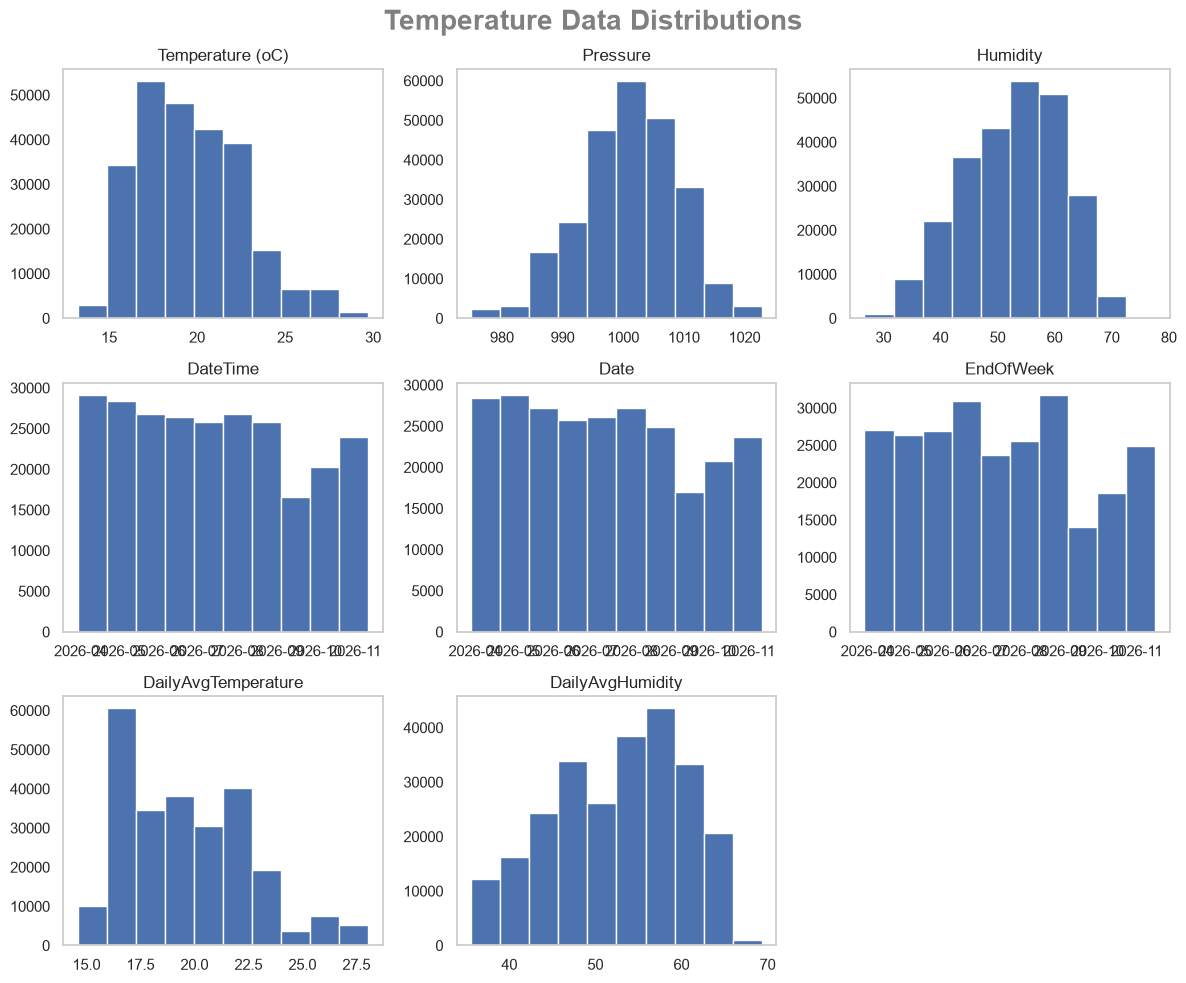

In [6]:
# show distributions
window_df.hist(
    grid=False, 
    figsize=(12, 10)
    );

plt.suptitle(
    "Temperature Data Distributions",
    fontsize=20,
    fontweight="bold",
    color="grey"
)

plt.tight_layout()

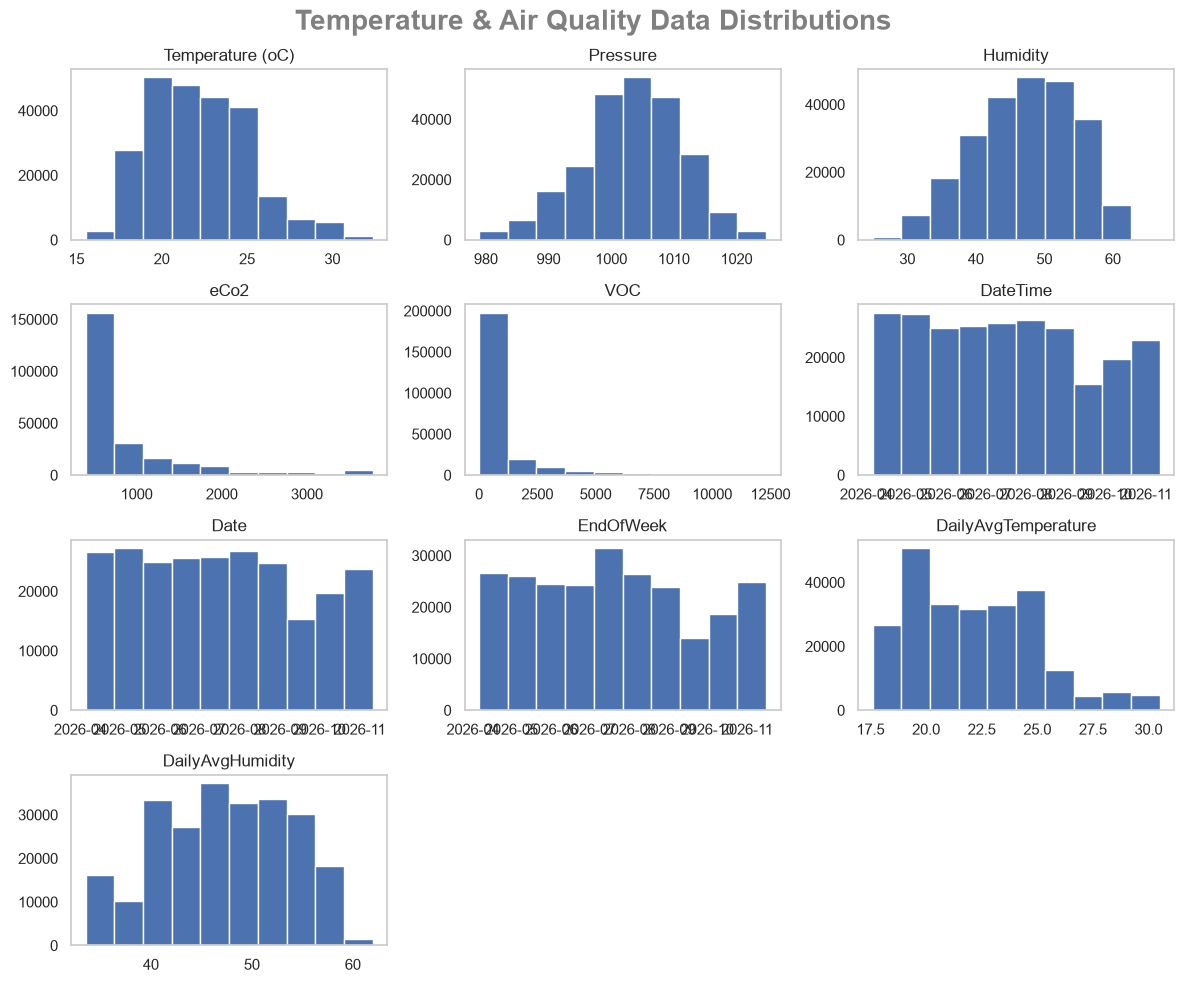

In [7]:
door_df.hist(
    grid=False, 
    figsize=(12, 10)
    );

plt.suptitle(
    "Temperature & Air Quality Data Distributions",
    fontsize=20,
    fontweight="bold",
    color="grey"
)
plt.tight_layout()

## EDA

1. Review how the data trends over time
2. Compute the difference between the two sensors - Does it get worse over times or specific periods?
3. When is humidity at its worse? (time during the day and month of the year)
4. Can we determine when humidity levels worsen? (ie the rate of change over time for when humidity levels increase)

#### Temperature Time Series

1


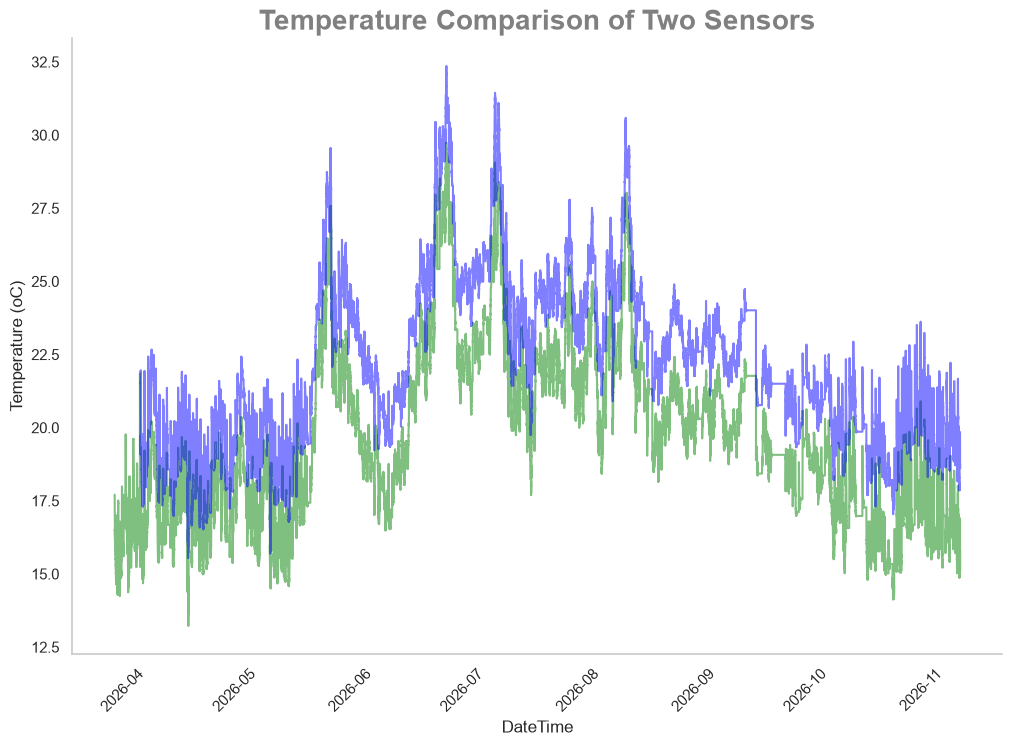

In [8]:
# review time series data trend over time

plot.plot_time_series(
    dfs=[window_df,door_df], 
    x_col="DateTime", 
    y_col=["Temperature (oC)"], 
    title="Temperature Comparison of Two Sensors",
    saved_name="Temperature Comparison of Two Sensors"
    )


1


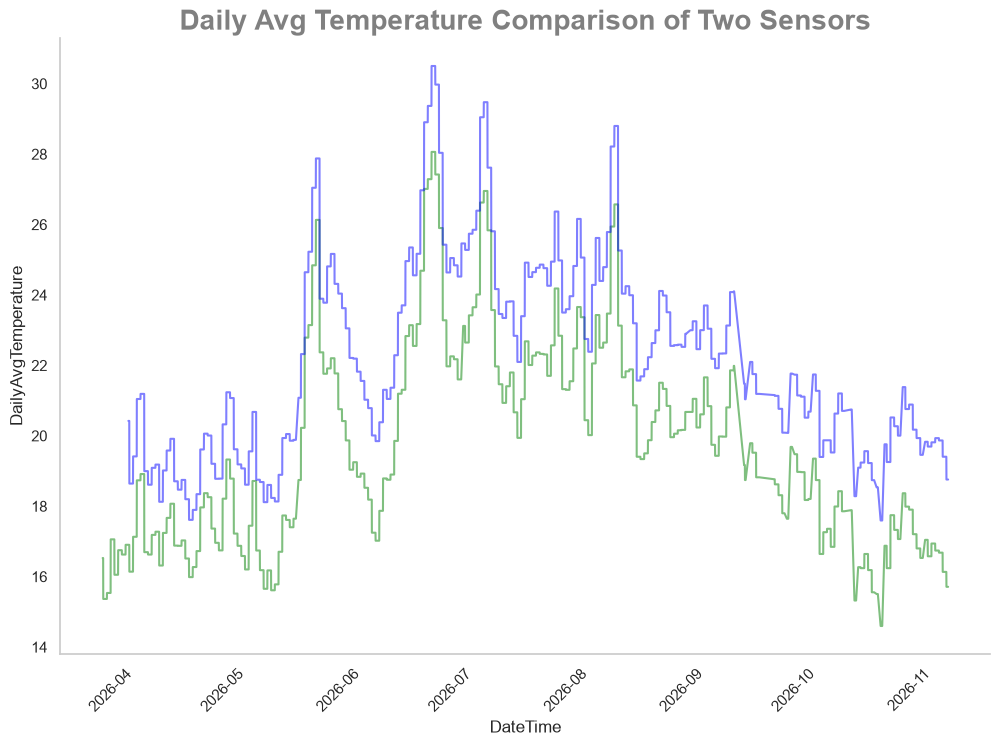

In [9]:
# show daily average time series plot
plot.plot_time_series(
    dfs=[window_df,door_df], 
    x_col="DateTime", 
    y_col=["DailyAvgTemperature"], 
    title="Daily Avg Temperature Comparison of Two Sensors",
    saved_name="Daily Avg Temperature Comparison of Two Sensors"
    )


##### **Notes**

1. There is evidence of cyclic behaviour -> The influence of time of the year and time of the day
2. The latest data shows that we are returing to temperatures of Apr 2026.


#### Humidity Time Series

1


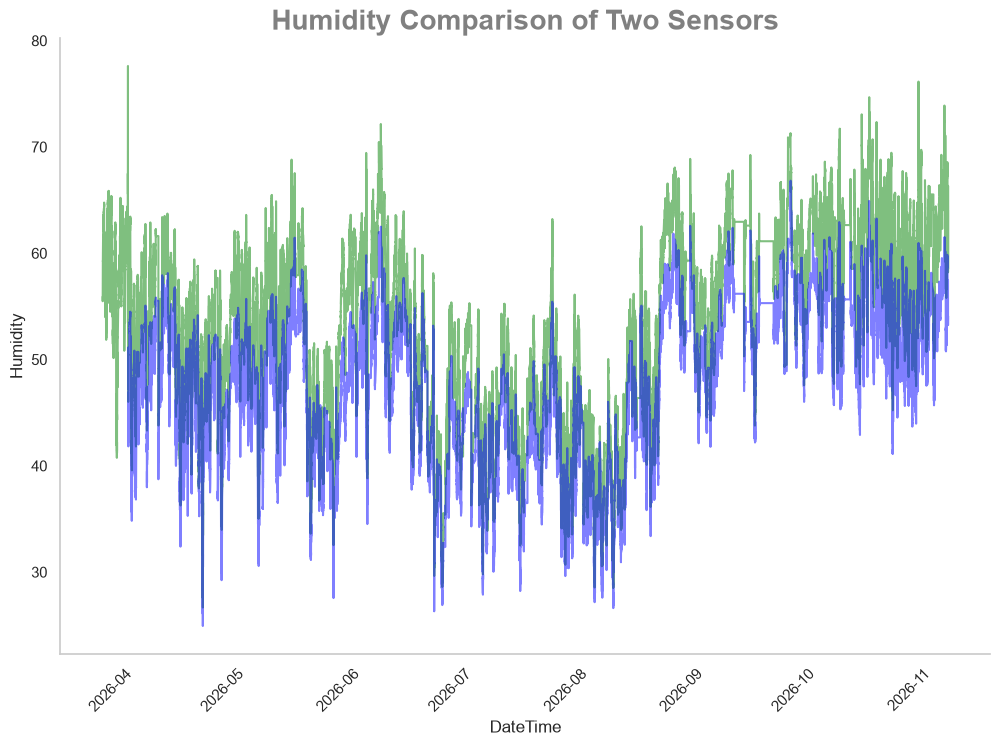

In [10]:
# now humidity
plot.plot_time_series(
    dfs=[window_df,door_df], 
    x_col="DateTime", 
    y_col=["Humidity"], 
    title="Humidity Comparison of Two Sensors",
    saved_name="Humidity Comparison of Two Sensors"
    )

1


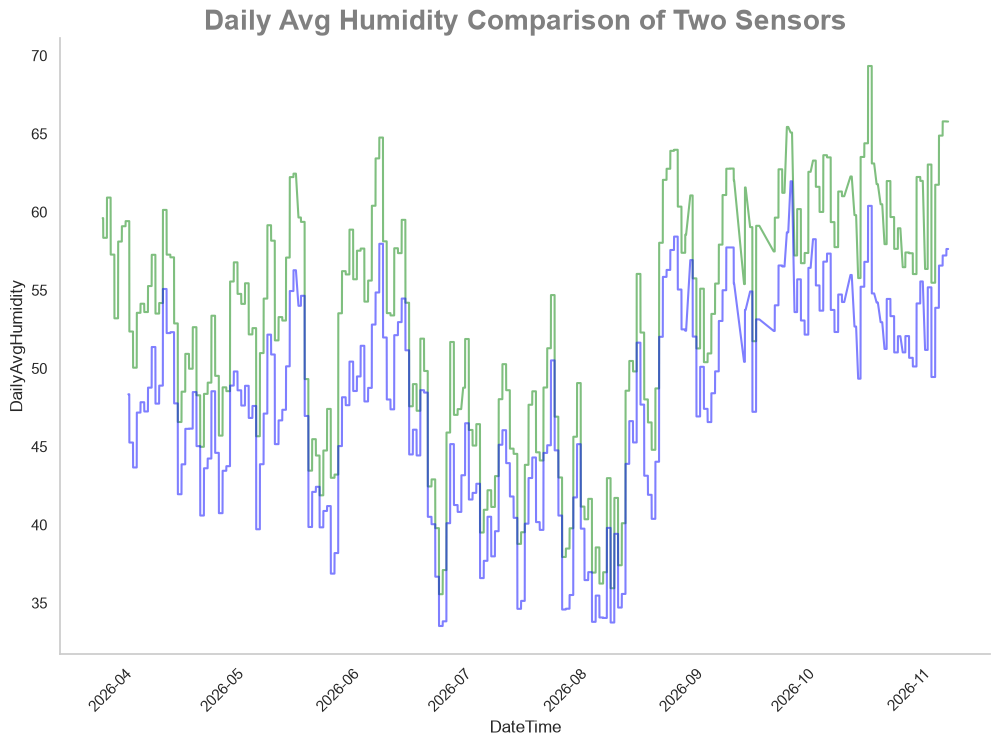

In [11]:
# Take the daily average and plot for ease of analysis
# show daily average time series plot
plot.plot_time_series(
    dfs=[window_df,door_df], 
    x_col="DateTime", 
    y_col=["DailyAvgHumidity"], 
    title="Daily Avg Humidity Comparison of Two Sensors",
    saved_name="Daily Avg Humidity Comparison of Two Sensors"
    )

##### **Notes**

1. Summer months appear to be less humid than colder months.
2. Humidity levels 

#### Temperature Sensor Drift

1


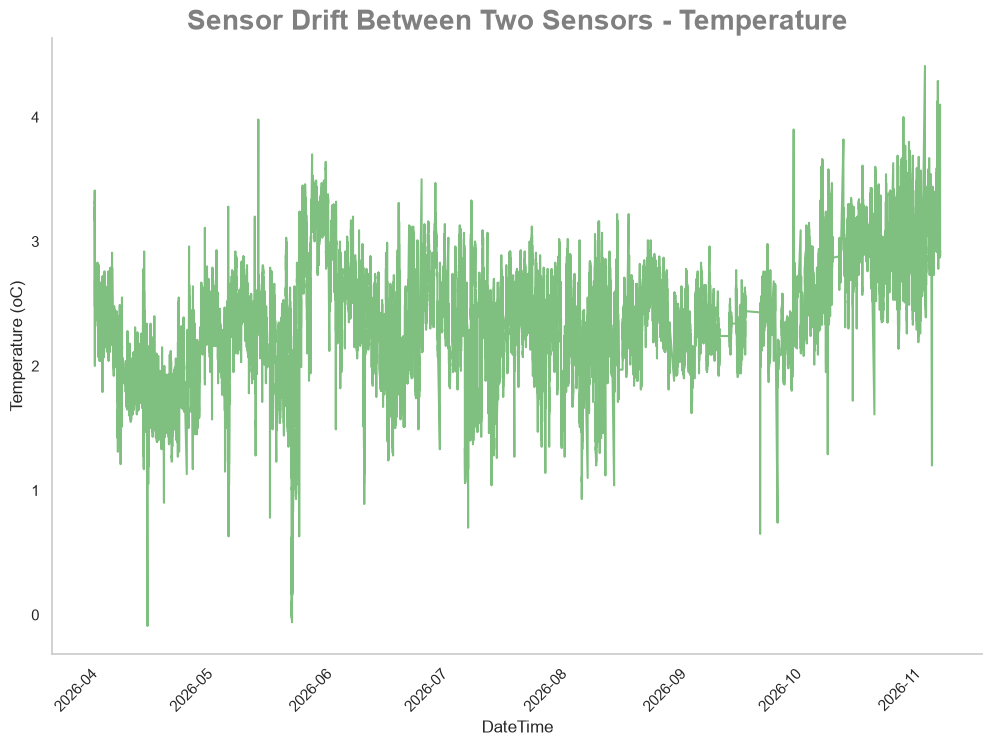

In [12]:
# How much of a difference is there between the two sensors?

tmp_sensor_drift = pd.DataFrame((door_df['Temperature (oC)'] - window_df['Temperature (oC)']).dropna())


plot.plot_time_series(
    dfs=[tmp_sensor_drift], 
    x_col="DateTime", 
    y_col=["Temperature (oC)"], 
    title="Sensor Drift Between Two Sensors - Temperature",
    saved_name="Sensor Drift Between Two Sensors"
    )

count    239404.000000
mean          2.383510
std           0.450813
min          -0.090000
25%           2.100000
50%           2.390000
75%           2.670000
max           4.410000
Name: Temperature (oC), dtype: float64 

Skewness: -0.15940218895329786
Kurtosis: 0.37592894730992743


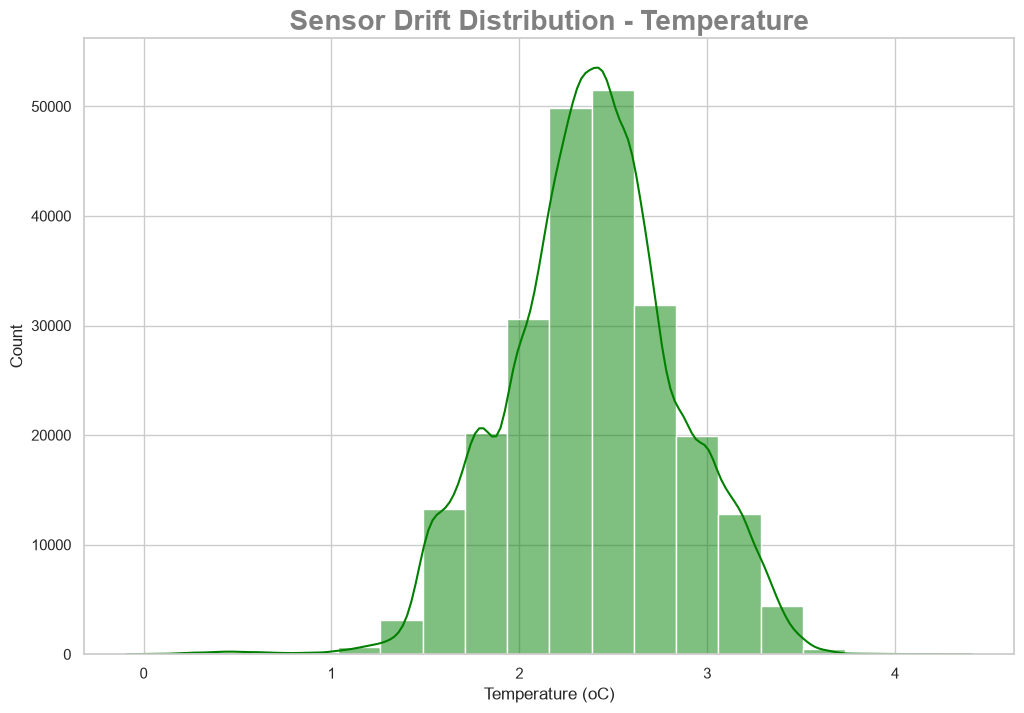

In [13]:
plot.plot_histogram(
    dfs=[tmp_sensor_drift],
    x_col="Temperature (oC)",
    saved_name="Sensor Drift Between Two Sensors",
    title="Sensor Drift Distribution - Temperature",
    bins=20
)

1


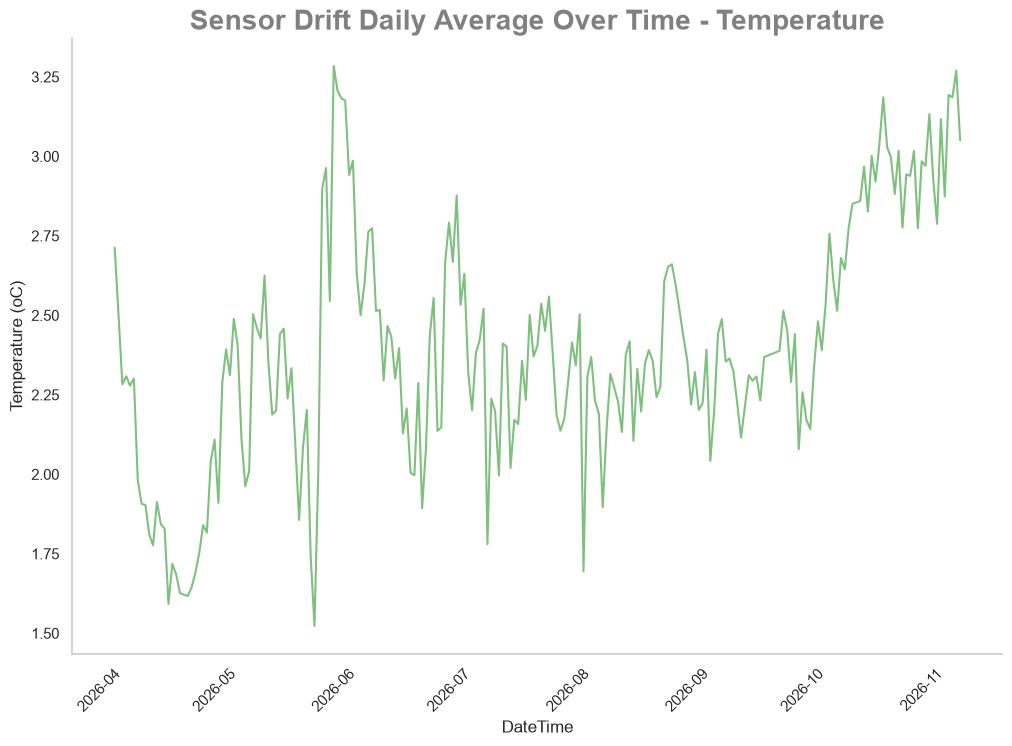

In [14]:
# How the sensor drift daily average changes over time
tmp_daily_avg_drift = tmp_sensor_drift.resample('1D').mean()


# plot the times series
plot.plot_time_series(
    dfs=[tmp_daily_avg_drift],
    x_col="DateTime",
    y_col=["Temperature (oC)"],
    title="Sensor Drift Daily Average Over Time - Temperature",
    saved_name="Sensor Drift Daily Average Over Time - Temperature"
    )



                            Sensor Drift (oC)  Daily Avg Door Temp (oC)  \
Sensor Drift (oC)                    1.000000                 -0.117047   
Daily Avg Door Temp (oC)            -0.117047                  1.000000   
Daily Avg Window Temp (oC)          -0.247511                  0.990995   

                            Daily Avg Window Temp (oC)  
Sensor Drift (oC)                            -0.247511  
Daily Avg Door Temp (oC)                      0.990995  
Daily Avg Window Temp (oC)                    1.000000  


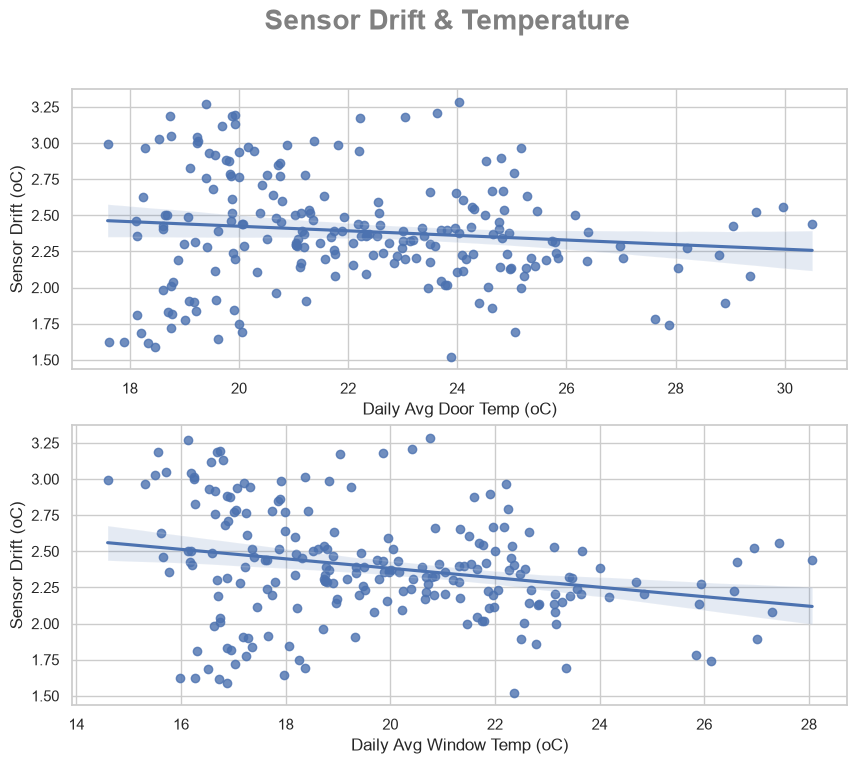

In [15]:
tmp_daily_avg_drift.rename(columns={'Temperature (oC)':'Sensor Drift (oC)'}, inplace=True)

# create daily avg features
tmp_daily_avg_drift['Daily Avg Door Temp (oC)'] = door_df['Temperature (oC)'].resample('D').mean()
tmp_daily_avg_drift['Daily Avg Window Temp (oC)'] = window_df['Temperature (oC)'].resample('D').mean()

plot.plot_relationships(
    df=tmp_daily_avg_drift,
    x_col=['Daily Avg Door Temp (oC)','Daily Avg Window Temp (oC)'],
    y_col='Sensor Drift (oC)',
    saved_name="Sensor Drift & Temperature",
    title="Sensor Drift & Temperature"
)

                            Sensor Drift (oC)  Daily Avg Door Temp (oC)  \
Sensor Drift (oC)                    1.000000                 -0.117047   
Daily Avg Door Temp (oC)            -0.117047                  1.000000   
Daily Avg Window Temp (oC)          -0.247511                  0.990995   
Daily Avg Door Humidity              0.355148                 -0.525751   
Daily Avg Window Humidity            0.457826                 -0.592850   

                            Daily Avg Window Temp (oC)  \
Sensor Drift (oC)                            -0.247511   
Daily Avg Door Temp (oC)                      0.990995   
Daily Avg Window Temp (oC)                    1.000000   
Daily Avg Door Humidity                      -0.559571   
Daily Avg Window Humidity                    -0.639514   

                            Daily Avg Door Humidity  Daily Avg Window Humidity  
Sensor Drift (oC)                          0.355148                   0.457826  
Daily Avg Door Temp (oC)              

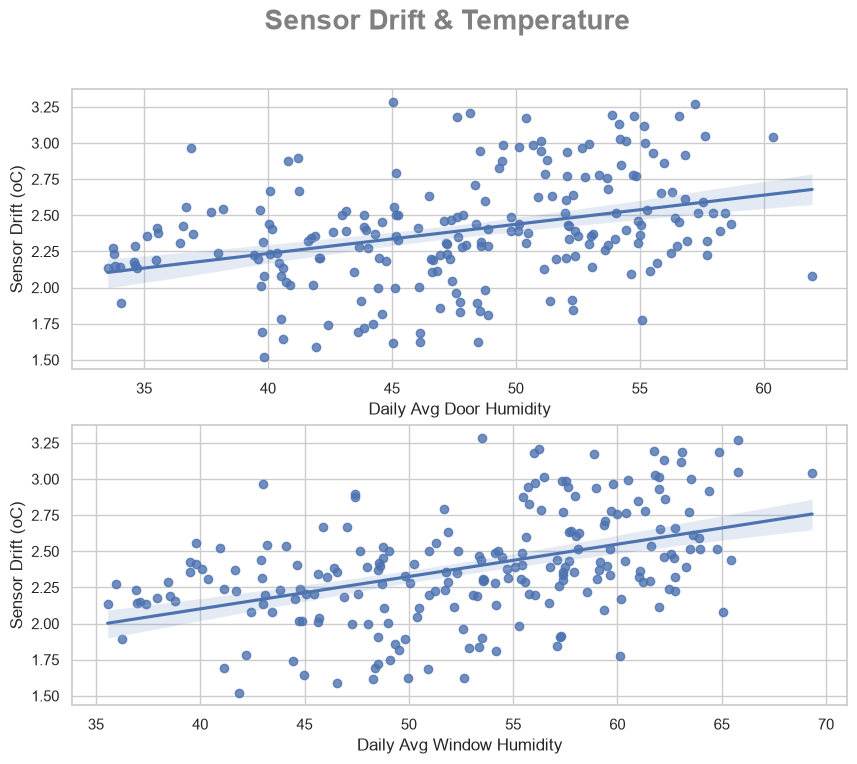

In [16]:
tmp_daily_avg_drift['Daily Avg Door Humidity'] = door_df['Humidity'].resample('D').mean()
tmp_daily_avg_drift['Daily Avg Window Humidity'] = window_df['Humidity'].resample('D').mean()

plot.plot_relationships(
    df=tmp_daily_avg_drift,
    x_col=['Daily Avg Door Humidity','Daily Avg Window Humidity'],
    y_col='Sensor Drift (oC)',
    saved_name="Sensor Drift & Temperature",
    title="Sensor Drift & Temperature"
)

##### **Notes**

1. The drift between 2 sensors appears to be getting worse as we draw closer to colder months - This suggests that one side of the room gets colder relative to the other side. However, more data is needed (Winter months) to determine if this is the case (a pattern should emergy where the difference remains around 2/3 degrees).
2. In addition to point one, the spikes in the daily avg sample appears to correlate with the spikes in temperature further evdidencing that one side of the room is more sensitive to temperature changes than the other. More evidence is required!
3. The counter argument to point one and two is the lack of evidence in correlation between drift and daily average temperature of each location.
4. There is a stronger relationship between Daily Avg Humidity levels and temperature drift, suggesting this factor may play a role. However, more analysis is required!
5. The positive relationship between Daily Avg Window Humidity and Sensor Drift suggests that the steady increase in humidity levels, the worse the drift get.

#### Humidity Sensor Drift

1


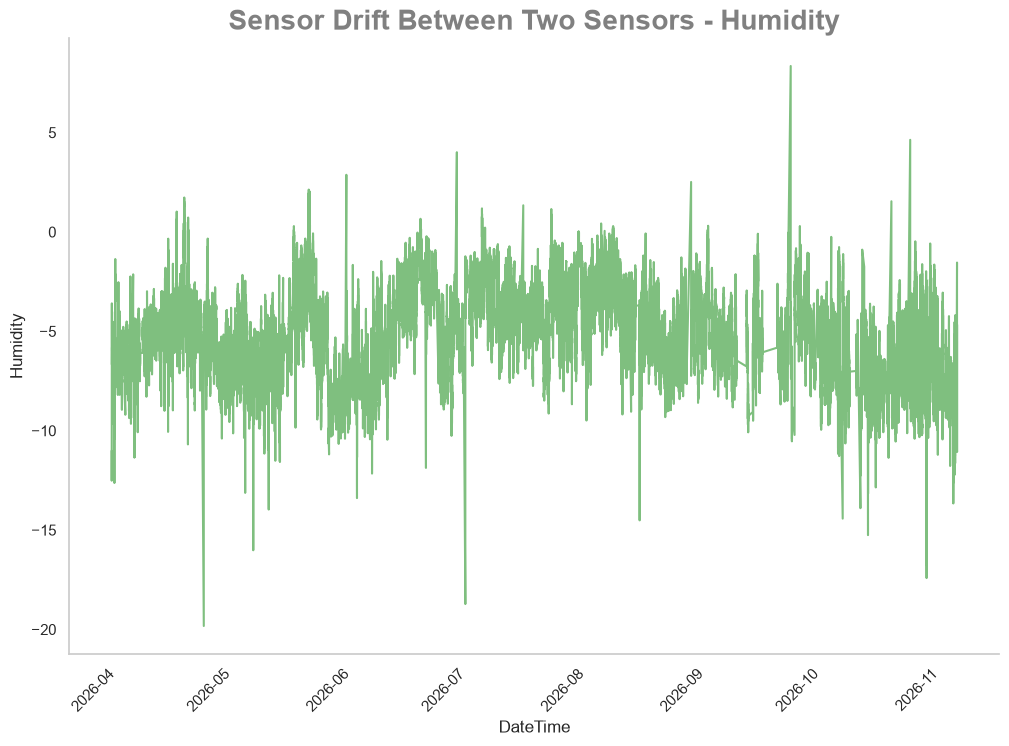

In [17]:
# How much of a difference is there between the two sensors humidity?

hum_sensor_drift = pd.DataFrame((door_df['Humidity'] - window_df['Humidity']).dropna())


plot.plot_time_series(
    dfs=[hum_sensor_drift], 
    x_col="DateTime", 
    y_col=["Humidity"], 
    title="Sensor Drift Between Two Sensors - Humidity",
    saved_name="Sensor Drift Between Two Sensors Over Time - Humidity"
    )

count    239404.000000
mean         -5.179848
std           2.082287
min         -19.828124
25%          -6.617188
50%          -5.126954
75%          -3.739260
max           8.352540
Name: Humidity, dtype: float64 

Skewness: -0.05992643489714637
Kurtosis: -0.09304326095323345


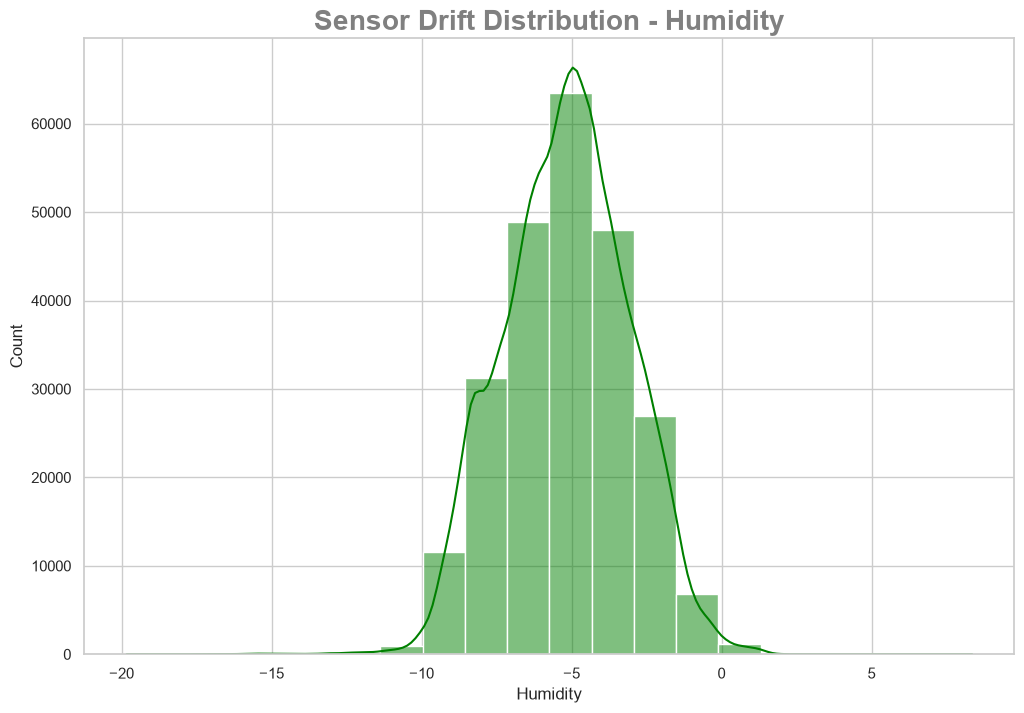

In [18]:
# show distribution
plot.plot_histogram(
    dfs=[hum_sensor_drift],
    x_col="Humidity",
    saved_name="Sensor Drift Distribution - Humidity",
    title="Sensor Drift Distribution - Humidity",
    bins=20
)

1


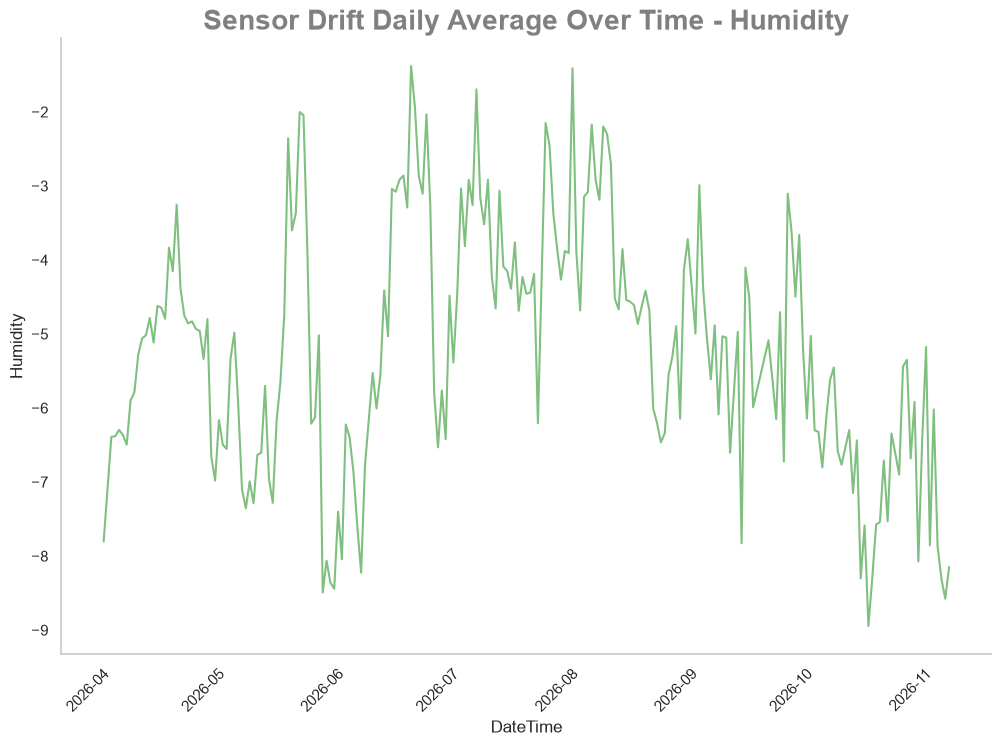

In [19]:
# review daily avg over time
hum_sensor_drift = hum_sensor_drift.resample('1D').mean()


# plot the times series
plot.plot_time_series(
    dfs=[hum_sensor_drift],
    x_col="DateTime",
    y_col=["Humidity"],
    title="Sensor Drift Daily Average Over Time - Humidity",
    saved_name="Sensor Drift Daily Average Over Time - Humidity"
    )

                            Humidity Sensor Drift  Daily Avg Door Temp (oC)  \
Humidity Sensor Drift                    1.000000                  0.652866   
Daily Avg Door Temp (oC)                 0.652866                  1.000000   
Daily Avg Window Temp (oC)               0.731008                  0.990995   

                            Daily Avg Window Temp (oC)  
Humidity Sensor Drift                         0.731008  
Daily Avg Door Temp (oC)                      0.990995  
Daily Avg Window Temp (oC)                    1.000000  


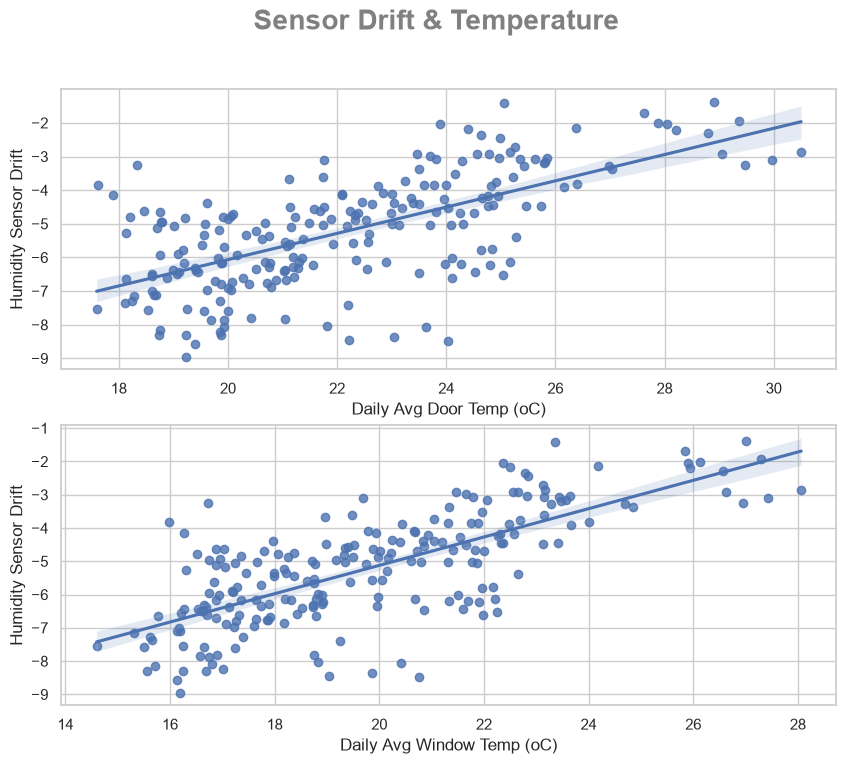

In [20]:
# what is the relationships between the two sensors temp and humidity drift?
hum_sensor_drift.rename(columns={'Humidity':'Humidity Sensor Drift'}, inplace=True)

# create daily avg features
hum_sensor_drift['Daily Avg Door Temp (oC)'] = door_df['Temperature (oC)'].resample('D').mean()
hum_sensor_drift['Daily Avg Window Temp (oC)'] = window_df['Temperature (oC)'].resample('D').mean()

plot.plot_relationships(
    df=hum_sensor_drift,
    x_col=['Daily Avg Door Temp (oC)','Daily Avg Window Temp (oC)'],
    y_col='Humidity Sensor Drift',
    saved_name="Sensor Drift & Temperature",
    title="Sensor Drift & Temperature"
)

##### Notes

1. The relationships plotted suggests that in the colder months, the drift between sensors for humidity gets worse meaning humidity levels become wrose on one side of the room compared to the other.
2. The wondow is more sensitive to drift in colder temperatures, meaning humidity is ~5% to 9% worse that the door sensor.
3. The change in humidity drift is more sensitive compared to temperature.

1


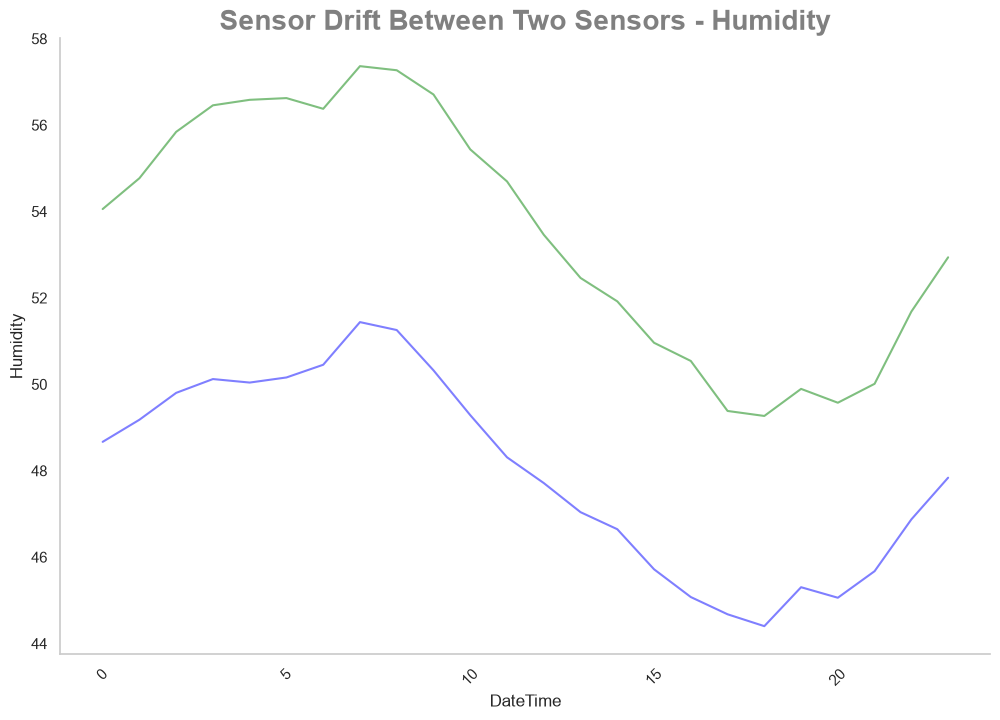

In [21]:
# lets do the same except this time focus on time of the day

hum_hourly_win = window_df.groupby(window_df.index.hour)['Humidity'].median().reset_index()
hum_hourly_door = door_df.groupby(door_df.index.hour)['Humidity'].median().reset_index()

# plot the line
plot.plot_time_series(
    dfs=[hum_hourly_win,hum_hourly_door], 
    x_col='DateTime', 
    y_col=["Humidity"], 
    title="Sensor Drift Between Two Sensors - Humidity",
    saved_name="Sensor Drift Between Two Sensors Over Time - Humidity"
    )

#### Notes

1. Humidity levels typically peak around 7am/8am.
2. The lowest levels typicall lie between 4pm and 6pm then augements as it goes into the night.

To tackle the humidity problem, it seems that the worse levels happens during the night/early morning. It would be interesting to see the data as we get into the winter!

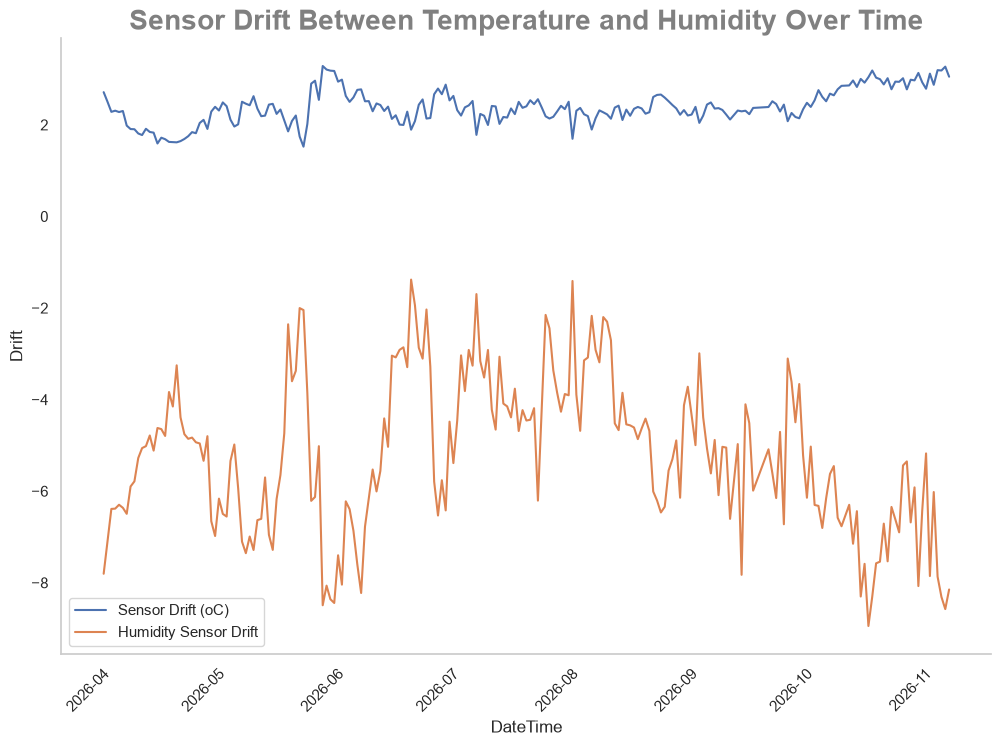

In [30]:
fig = plt.figure(figsize=(12,8))

hum_and_tmp_drift = pd.concat(
    [
        tmp_daily_avg_drift[['Sensor Drift (oC)']], 
        hum_sensor_drift[['Humidity Sensor Drift']]
        ], 
        axis=1
)

for feature in ['Sensor Drift (oC)','Humidity Sensor Drift']:
    sns.lineplot(
        data=hum_and_tmp_drift,
        x=hum_and_tmp_drift.index,
        y=feature,
        label=feature
    )

plt.legend()

# clean up for standrad settings
plot.plot_cleanup(
    title="Sensor Drift Between Temperature and Humidity Over Time",
    xlabel="DateTime",
    ylabel="Drift"
)

# save the image
plot.save_image(
    file_name="Sensor Drift Between Temperature and Humidity Over Time",
    fig=fig
)

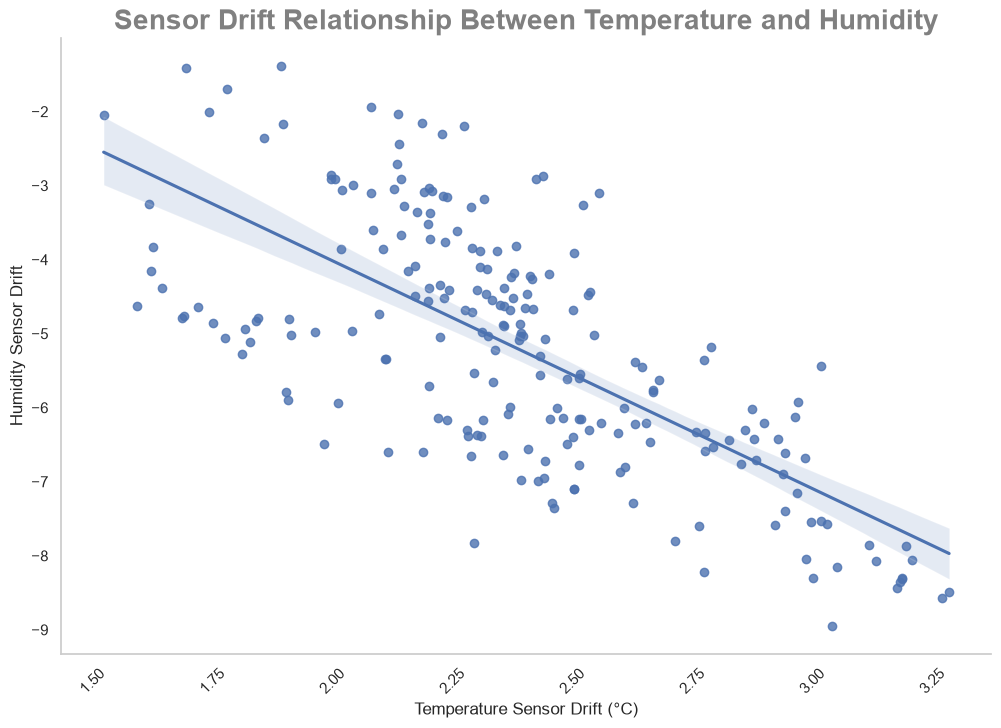

In [31]:
fig = plt.figure(figsize=(12,8))


sns.regplot(
    data=hum_and_tmp_drift.dropna(),
    x='Sensor Drift (oC)',
    y='Humidity Sensor Drift',
    label='Humidity Sensor Drift'
)

plot.plot_cleanup(
    title="Sensor Drift Relationship Between Temperature and Humidity",
    xlabel="Temperature Sensor Drift (°C)",
    ylabel="Humidity Sensor Drift"
)

# save the image
plot.save_image(
    file_name="Sensor Drift Relationship Between Temperature and Humidity",
    fig=fig
)